<!-- d2l:prose id=integration-md-1 fw=all -->

# Sampling by Integration

A network trained along a Gaussian path predicts, at every noise level $t \in [0, 1]$, the marginal velocity $\mathbf{u}_t(\mathbf{x})$ (or equivalently the score $\nabla \log p_t(\mathbf{x})$). Why does integrating this deterministic vector field backward from $\mathbf{x}_1 \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ at $t = 1$ to $t = 0$ produce samples distributed according to $p_0$, with the exact mode weights $0.5, 0.3, 0.2$ that fixed-level Langevin chains missed?

The guarantee comes from the *continuity equation* of probability transport. Because each conditional Gaussian cloud $p_t(\mathbf{x} \mid \mathbf{x}_0)$ satisfies conservation of mass under its conditional velocity, averaging over $p(\mathbf{x}_0)$ shows that the marginal density $p_t$ is transported by the posterior-mean velocity $\mathbf{u}_t(\mathbf{x})$. @song2021score formulated deterministic sampling via this *probability-flow ODE*, while @ho2020denoising sampled via a stochastic reverse Markov chain; as we will show, each ancestral step of DDPM decomposes to first order into an Euler step of the probability-flow ODE plus a Langevin step at the current noise level. In this section we derive both samplers, express the ODE in path-agnostic $(\bar{\mathbf{x}}, \bar\sigma)$ coordinates, and compare the trained networks against the exact oracle on the three-mode mixture.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
torch.set_float32_matmul_precision('high')  # tf32 matmuls on tensor cores

<!-- d2l:prose id=integration-md-2 fw=all -->

Each section runs as a notebook of its own, so the cell below rebuilds what we need from that section: the three-mode mixture and two of its paths, the variance-preserving (VP) path and the linear path. It also defines the exact posterior means $(\hat{\mathbf{x}}_0, \hat{\boldsymbol\epsilon})$ of the mixture at any point and noise level, which the code calls `oracle`, as in the previous section. Then it retrains two networks, one for each sampler of this section: a velocity model on the linear path for the flow, and a noise model on the VP path for DDPM's chain. The recipe is that of the previous section with half as many steps, and twenty thousand steps suffice. To show this, the cell prints the mean training loss over the last thousand steps, to be compared with the floors of the previous section, about $4.9$ for the velocity and $0.54$ for the noise. Both trainings together take about a minute on one GPU.

In [3]:
device = d2l.try_gpu()
mix = d2l.GaussianMixture.three_modes(device)
vp, linear = d2l.GaussianPath.vp(), d2l.GaussianPath.linear()

def oracle(x, alpha, sigma):
    """The exact posterior means (x0_hat, eps_hat) of the mixture at x."""
    x0_hat = mix.posterior_mean(x, alpha, sigma)
    a, s = (torch.as_tensor(v, device=x.device).reshape(-1, 1)
            for v in (alpha, sigma))
    return x0_hat, (x - a * x0_hat) / s

num_steps = 20_000
torch.manual_seed(1)
_, ema_v, losses_v = d2l.train_regression(
    d2l.TimeMLP(256, 3).to(device), d2l.regression_loss(linear, 'velocity'),
    lambda: mix.sample(512), num_steps, cosine=True, ema_half_life=700)
torch.manual_seed(2)
_, ema_eps, losses_eps = d2l.train_regression(
    d2l.TimeMLP(256, 3).to(device), d2l.regression_loss(vp, 'eps'),
    lambda: mix.sample(512), num_steps, cosine=True, ema_half_life=700)
print(f'loss over the last 1,000 steps: velocity '
      f'{losses_v[-1000:].mean().item():.3f}, '
      f'noise {losses_eps[-1000:].mean().item():.3f}')

loss over the last 1,000 steps: velocity 4.919, noise 0.537


<!-- d2l:prose id=integration-md-3 fw=all -->

Both losses are at their floors: neither network has much left to learn from the regression. How close they come to the oracle where it matters, in the samples, is the subject of the last part of this section.

## Transport of Probability Mass

Let us start with what a velocity field does to a density. Take a cloud of points distributed as $p_t$ and let every point move for a short time with the velocity $\mathbf{u}_t(\mathbf{x})$ at its position. No point is created or destroyed, so the density at $\mathbf{x}$ can change only by the mass that flows in minus the mass that flows out. The mass crossing a small window per unit time is the density times the velocity, $p_t \mathbf{u}_t$. What this flow carries out of a small box around $\mathbf{x}$, net and per unit volume, is its divergence $\nabla \cdot (p_t \mathbf{u}_t) = \sum_i \partial (p_t u_{t,i}) / \partial x_i$, and the density there falls at exactly that rate. This is the *continuity equation* of fluid mechanics:

$$
\frac{\partial p_t(\mathbf{x})}{\partial t} = -\nabla \cdot \big(p_t(\mathbf{x})\, \mathbf{u}_t(\mathbf{x})\big).
$$

When a density and a field satisfy it, points that follow the field keep the density of the path at every time, forward or backward. Does the marginal velocity of that section satisfy it together with $p_t$?

Take one clean point $\mathbf{x}_0$ first. Its noisy versions form the Gaussian cloud $\mathcal{N}(\alpha_t \mathbf{x}_0, \sigma_t^2 \mathbf{I})$, and each point of the cloud moves with the conditional velocity $\dot\alpha_t \mathbf{x}_0 + \dot\sigma_t \boldsymbol\epsilon$, where $\boldsymbol\epsilon = (\mathbf{x} - \alpha_t \mathbf{x}_0)/\sigma_t$ is the noise that put it at $\mathbf{x}$. This field, call it $\mathbf{u}_t(\mathbf{x} \mid \mathbf{x}_0)$, moves this one cloud correctly: a point that keeps its noise $\boldsymbol\epsilon$ sits at $\alpha_t \mathbf{x}_0 + \sigma_t \boldsymbol\epsilon$ at every time, a draw from the cloud, so the cloud and its field satisfy the continuity equation. The marginal density $p_t$ is the average of the clouds over the data, and the equation is linear in the density, so averaging the clouds' equations gives one for $p_t$ with the averaged mass flow on the right. By Bayes' rule, $p(\mathbf{x}_0)\, p_t(\mathbf{x} \mid \mathbf{x}_0) = p_t(\mathbf{x})\, p(\mathbf{x}_0 \mid \mathbf{x}_t = \mathbf{x})$, so this flow is

$$
\begin{aligned}
\mathbb{E}_{\mathbf{x}_0}\big[p_t(\mathbf{x} \mid \mathbf{x}_0)\, \mathbf{u}_t(\mathbf{x} \mid \mathbf{x}_0)\big]
&= p_t(\mathbf{x})\, \mathbb{E}\big[\dot\alpha_t \mathbf{x}_0 + \dot\sigma_t \boldsymbol\epsilon \,\big|\, \mathbf{x}_t = \mathbf{x}\big] \\
&= p_t(\mathbf{x})\, \mathbf{u}_t(\mathbf{x}).
\end{aligned}
$$

The posterior average in the middle is how the marginal velocity was defined. So the mass that all the clouds together carry across $\mathbf{x}$ is the density there times the marginal velocity, and $p_t$ and $\mathbf{u}_t$ satisfy the continuity equation. The samplers of the following sections rest on this result. that section proves it with the conditions it needs.

A reader may object that averaged velocities do not produce averaged trajectories, and the objection is right. The conditional paths (straight lines, on the linear path) pass through every point at every time and cross one another everywhere, while two trajectories of one field never meet at the same time, because a point has only one velocity at a given time. A sample that follows $\mathbf{u}_t$ follows no conditional path at all. the figure draws both kinds of curve for a mixture of two Gaussians in one dimension: the noise drawn in orange belongs to a clean point in the right mode, and its trajectory ends in the left one. The argument above says nothing about single trajectories; it says that the field reproduces the *density* at every time, and the density is all a sampler needs.

![Conditional paths and trajectories on the linear path, for a mixture of two Gaussians in one dimension. Time runs from the data at $t = 0$ (bottom) to the noise at $t = 1$ (top), and the shading is the density $p_t$. (a) The conditional paths of nine pairs of a clean point $\mathbf{x}_0$ (cross) and a noise $\boldsymbol\epsilon$ (dot) are straight lines, and they cross. (b) The trajectories of the marginal field $\mathbf{u}_t$ from the same nine noises never meet. The orange noise ends in the right mode along its conditional path and in the left mode along its trajectory.](../img/mdl-diffusion-crossing-paths.svg)

This answers our question. Solved exactly, the flow cannot get the mode weights wrong, because it conserves mass at every instant: half of the noise must end in the mode of weight one half. The Langevin chains would have kept the data distribution in place once they reached it, but nothing carried them there across the valleys. The annealed ladder crossed the valleys at its coarse levels, where the noise fills them in, but how many levels and steps it needed was ours to guess. The flow starts from a density it knows, the standard Gaussian, and moves it into the data with a guarantee. Two things can still go wrong: our steps only approximate the solution, and our network only approximates the field. The rest of the section measures both.

The sampler, then, draws $\mathbf{x}$ from $p_1 = \mathcal{N}(\mathbf{0}, \mathbf{I})$ and solves the ordinary differential equation

$$
\frac{d\mathbf{x}}{dt} = \mathbf{u}_t(\mathbf{x}), \qquad \textrm{from } t = 1 \textrm{ down to } t = 0.
$$

At every time its solution is a draw from $p_t$, and at $t = 0$ a draw from the data. @song2021score called it the *probability-flow ODE* (that section). Nothing random happens after the start: the whole randomness of a sample lies in its starting point.

## Euler's Method on the Probability-Flow ODE

An ODE is solved numerically by many small straight steps. *Euler's method* (that section) cuts the time from $1$ to $0$ into $K$ equal steps and at each one moves the point against the velocity, $\mathbf{x} \leftarrow \mathbf{x} - \mathbf{u}_t(\mathbf{x})/K$ at $t = 1, 1 - 1/K, \ldots, 1/K$. How many steps does the flow need? General data are hard to reason about, so we start from data that make the answer obvious and build up, as @Nakkiran.Bradley.Zhou.ea.2025 do.

### From One Point to the Data Mean

Let the data be a single point $\mathbf{x}_0$. On the linear path ($\alpha_t = 1 - t$, $\sigma_t = t$) a point $\mathbf{x}$ at time $t$ carries the noise $\boldsymbol\epsilon = (\mathbf{x} - (1 - t)\mathbf{x}_0)/t$ and moves with velocity $\boldsymbol\epsilon - \mathbf{x}_0 = (\mathbf{x} - \mathbf{x}_0)/t$. Every trajectory is a straight line into $\mathbf{x}_0$ at constant speed, and a single Euler step of length one, $\mathbf{x} \leftarrow \mathbf{x} - \mathbf{u}_1(\mathbf{x}) = \mathbf{x}_0$, is exact. With two data points the field is the posterior-weighted average of two such straight fields, and the trajectories bend where the posterior switches from one point to the other (that section).

Any distribution is a mixture of point masses, and its trajectories bend wherever the posterior is undecided. At $t = 1$ it is entirely undecided. A point of pure noise says nothing about the clean point it came from, so the posterior is the prior and

$$
\mathbf{u}_1(\mathbf{x}) = \mathbb{E}\big[\boldsymbol\epsilon - \mathbf{x}_0 \,\big|\, \mathbf{x}_1 = \mathbf{x}\big] = \mathbf{x} - \mathbb{E}[\mathbf{x}_0].
$$

One Euler step of length one therefore sends every start to the mean of the data. For our mixture we can predict the result before running anything: $0.5\,(-2.5, -1.5) + 0.3\,(2.5, -1.5) + 0.2\,(0, 2.5) = (-0.5, -0.7)$, a point between the modes, more than four standard deviations from the nearest one. To see what more steps do, we run Euler's method on the exact field of the mixture on the linear path, `mix.velocity`, from five fixed starts, the origin and four points at distance $1.5$ from it, with one, ten and a hundred steps.

In [4]:
@torch.no_grad()
def euler(net, x, steps):
    """Euler's method on dx/dt = net(x, t), from t = 1 down to t = 0."""
    for k in range(steps, 0, -1):
        t = torch.full((len(x),), k / steps, device=x.device)
        x = x - net(x, t) / steps
    return x

starts = torch.tensor([[0.0, 0.0], [1.5, 0.0], [-1.5, 0.0], [0.0, 1.5],
                       [0.0, -1.5]], device=device)
ends = torch.stack([starts] + [euler(mix.velocity, starts, steps)
                               for steps in (1, 10, 100)], 1)
print('start          1 step          10 steps        100 steps')
for row in ends.tolist():
    print('  '.join(f'({x:5.2f}, {y:5.2f})' for x, y in row))

start          1 step          10 steps        100 steps
( 0.00,  0.00)  (-0.50, -0.70)  (-1.91, -1.27)  (-1.98, -1.30)
( 1.50,  0.00)  (-0.50, -0.70)  ( 2.73, -1.34)  ( 2.90, -1.36)
(-1.50,  0.00)  (-0.50, -0.70)  (-2.92, -1.38)  (-3.06, -1.40)
( 0.00,  1.50)  (-0.50, -0.70)  (-0.11,  2.59)  (-0.09,  2.77)
( 0.00, -1.50)  (-0.50, -0.70)  (-1.98, -2.06)  (-2.05, -2.17)


<!-- d2l:prose id=integration-md-4 fw=all -->

The one-step column is the prediction: all five starts land on $(-0.50, -0.70)$, where no data lie. Ten steps already put every start inside a mode, within about $0.2$ of where a hundred steps end, and always on the near side, closer to the data mean; the coarse steps keep a little of the one-step error. Now look at *which* mode each start reaches. The origin, the start below it and the start to its left all end in the heaviest mode, the start on the right in the mode on the right, the one above in the top mode. This is the conservation of mass at work: half of the standard Gaussian must end in the mode of weight one half, so that mode collects the largest region of starts, here including the center of the Gaussian. Nor do the ends sit at the mode centers. The origin ends at $(-1.98, -1.30)$, about one standard deviation of a mode from its center. The flow is a map from noise to data, and every start has a sample of its own.

### Coordinates for Every Path

Euler steps in $t$ depend on the path. On the VP path the noise level is still $\sigma_t = 0.96$ at $t = 0.5$ and has fallen to $0.32$ by $t = 0.1$ (that section): the first half of the time removes almost no noise, and two thirds of it go in the next two fifths of the time. A step in $t$ moves at the rate it finds at its start, and on such a curve a long step misses badly (Exercise 1). The library's sampler therefore takes its steps in coordinates in which every Gaussian path looks the same. Divide the path by $\alpha_t$:

$$
\bar{\mathbf{x}} = \frac{\mathbf{x}_t}{\alpha_t} = \mathbf{x}_0 + \bar\sigma\, \boldsymbol\epsilon,
\qquad \bar\sigma = \frac{\sigma_t}{\alpha_t}.
$$

In these coordinates the data keep their scale and only the noise grows, from $\bar\sigma = 0$ at the data to $\bar\sigma = \infty$ at pure noise. Every path becomes the variance-exploding (VE) path of that section, the one the annealed ladder walked down, and $\bar\sigma$ is its noise level. @Karras.Aittala.Aila.ea.2022 sample all paths this way. Here the bar means division by $\alpha_t$, not the square it means in DDPM's $\bar\alpha_t = \alpha_t^2$ (the table). Along one conditional path $\bar{\mathbf{x}}$ moves in a straight line in $\bar\sigma$ with slope $\boldsymbol\epsilon$. The marginal field is the posterior average of these slopes, the noise prediction:

$$
\frac{d\bar{\mathbf{x}}}{d\bar\sigma} = \hat{\boldsymbol\epsilon}(\bar{\mathbf{x}}).
$$

Taking the posterior mean of the first equation gives $\bar{\mathbf{x}}_t = \hat{\mathbf{x}}_0 + \bar\sigma_t \hat{\boldsymbol\epsilon}$, so an Euler step from $\bar\sigma_t$ down to $\bar\sigma_s$ is $\bar{\mathbf{x}}_s = \bar{\mathbf{x}}_t + (\bar\sigma_s - \bar\sigma_t)\hat{\boldsymbol\epsilon} = \hat{\mathbf{x}}_0 + \bar\sigma_s \hat{\boldsymbol\epsilon}$, and multiplied by $\alpha_s$,

$$
\mathbf{x}_s = \alpha_s\, \hat{\mathbf{x}}_0 + \sigma_s\, \hat{\boldsymbol\epsilon}.
$$

Thus a step predicts the clean point and the noise, and places them at the next level. that section will meet this update again under the name DDIM. On the linear path it is the Euler step in $t$ itself, as substituting $\mathbf{x}_t = (1 - t)\hat{\mathbf{x}}_0 + t\hat{\boldsymbol\epsilon}$ into $\mathbf{x}_t - (t - s)(\hat{\boldsymbol\epsilon} - \hat{\mathbf{x}}_0)$ shows. On other paths it is a different method, and for data made of one point it is exact at any step length, where the Euler step in $t$ on the VP stride above is far off (Exercise 1).

`ode_sample` takes these steps through a list of levels $\bar\sigma$, which `sigma_bars` computes from the path's grid in $t$. At pure noise $\bar\sigma$ is infinite and $\bar{\mathbf{x}}$ undefined, but the step needs only $\hat{\mathbf{x}}_0$ and $\hat{\boldsymbol\epsilon}$, which the predictor computes from the noise itself, so the first step starts from $\mathbf{x}$.

In [5]:
@d2l.add_to_class(d2l.GaussianPath)
def sigma_bars(self, steps):
    """sigma_bar = sigma / alpha on the grid of steps; inf where alpha = 0."""
    a, s = self.grid(steps)
    return [s_k / a_k if a_k > 0 else math.inf for a_k, s_k in zip(a, s)]

def pred_bar(pred, xb, r):
    """pred at x = alpha x_bar, sigma_bar = r; at r = inf, x_bar is noise."""
    if math.isinf(r):
        return pred(xb, 0.0, 1.0)
    a = 1 / math.sqrt(1 + r ** 2)
    return pred(xb * a, a, r * a)

@torch.no_grad()
def ode_sample(pred, x, sigma_bars):
    """Euler (= DDIM) on d x_bar / d sigma_bar = eps, from x to data; x is the
    noisy point at the first level, unit-variance scale (noise if inf)."""
    r0 = sigma_bars[0]
    xb = x if math.isinf(r0) else x * math.sqrt(1 + r0 ** 2)  # x / alpha
    for r_t, r_s in zip(sigma_bars[:-1], sigma_bars[1:]):
        x0, eps = pred_bar(pred, xb, r_t)
        xb = x0 + r_s * eps                    # the Euler (= DDIM) step
    return xb

<!-- d2l:prose id=integration-md-5 fw=all -->

A sampler needs $\hat{\mathbf{x}}_0$ and $\hat{\boldsymbol\epsilon}$ at any $(\alpha, \sigma)$, and `make_pred` turns a trained network of any kind into such a predictor. In this section each network runs on its own path, and `make_pred` only converts its prediction into the pair. Later sections run a network on another path's grid; then `make_pred` first finds the time on the network's own path with the same log-SNR (by bisection in `time_at`) and rescales the point to that path. A noise model has one blind spot. At pure noise, $\alpha = 0$, the clean point $\hat{\mathbf{x}}_0 = (\mathbf{x} - \sigma\hat{\boldsymbol\epsilon})/\alpha$ is undefined, so a noise model cannot start a sampler on the linear path; on the VP path $\alpha$ stays positive, about $0.007$ at $t = 1$, and that is where we use it.

In [6]:
@d2l.add_to_class(d2l.GaussianPath)
def time_at(self, log_snr):
    """The time with a given log-SNR, by bisection (lambda_t falls in t)."""
    lo, hi = torch.zeros_like(log_snr), torch.ones_like(log_snr)
    for _ in range(50):
        mid = (lo + hi) / 2
        later = self.log_snr(mid) > log_snr      # the answer lies after mid
        lo, hi = torch.where(later, mid, lo), torch.where(later, hi, mid)
    return (lo + hi) / 2

def make_pred(net, path, kind):
    """pred(x, alpha, sigma) -> (x0, eps) from net(x, t) of a kind on path."""
    def pred(x, alpha, sigma):
        log_snr = 2 * math.log(alpha / sigma) if alpha > 0 else -math.inf
        t = path.time_at(torch.tensor(log_snr, dtype=torch.float64))
        x = x * (path.sigma(t).item() / sigma)  # the same point on our path
        t = torch.full((len(x),), t.item(), device=x.device)
        return path.x0_eps(kind, net(x, t), x, t)
    return pred

<!-- d2l:prose id=integration-md-6 fw=all -->

### The Learned Field

Does the trained velocity network behave like the exact field, landing on the data mean after one step and in the modes after ten? We run it from $2{,}000$ standard Gaussian starts with one, ten and a hundred steps of `ode_sample`. Two more rows make the numbers readable: $2{,}000$ draws from the data themselves, the gray points of the plot, and the oracle taking the same ten steps from the same starts. Last, the cell runs `ode_sample` with the oracle against the plain Euler loop with `mix.velocity`. On the linear path the two take identical steps, so they should agree up to rounding.

one step: mean [-0.511, -0.736] std [0.036, 0.027]
              data: {'weights': [0.517, 0.292, 0.192], 'stray': 0.0145, 'spread': 0.488}
 10 steps, network: {'weights': [0.522, 0.273, 0.206], 'stray': 0.0315, 'spread': 0.447}
100 steps, network: {'weights': [0.512, 0.278, 0.211], 'stray': 0.0125, 'spread': 0.475}
  10 steps, oracle: {'weights': [0.522, 0.273, 0.206], 'stray': 0.019, 'spread': 0.459}
ode_sample against the loop on the exact field: 9e-05


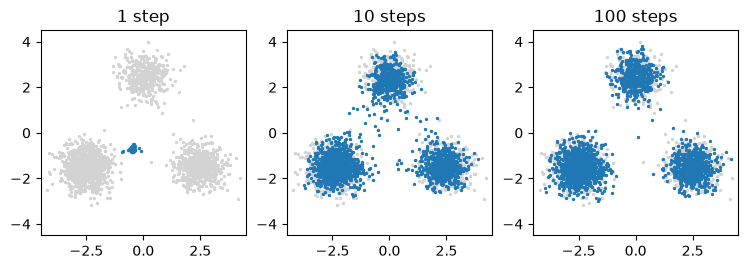

In [7]:
torch.manual_seed(3)
x_T = torch.randn(2000, 2, device=device)
pred_v = make_pred(ema_v, linear, 'velocity')
samples = [ode_sample(pred_v, x_T, linear.sigma_bars(steps))
           for steps in (1, 10, 100)]
data = mix.sample(2000)
print('one step: mean', [round(v, 3) for v in samples[0].mean(0).tolist()],
      'std', [round(v, 3) for v in samples[0].std(0).tolist()])
print(f'{"data":>18}:', mix.summary(data))
for steps, x in zip((10, 100), samples[1:]):
    print(f'{steps:>3} steps, network:', mix.summary(x))
print('  10 steps, oracle:',
      mix.summary(ode_sample(oracle, x_T, linear.sigma_bars(10))))
exact = (ode_sample(oracle, x_T, linear.sigma_bars(100))
         - euler(mix.velocity, x_T, 100)).abs().max().item()
print(f'ode_sample against the loop on the exact field: {exact:.0e}')
d2l.scatter_panels(samples, ['1 step', '10 steps', '100 steps'], data=data);

<!-- d2l:prose id=integration-md-7 fw=all -->

A single step collapses every initial point onto the data mean $\approx (-0.5, -0.7)$ (up to a small network approximation error of a few hundredths at $t = 1$). Ten Euler steps separate the three modes with weights near $0.5, 0.3, 0.2$, but leave $\approx 3\%$ strays (versus $1.1\%$–$1.5\%$ for the true data) and slightly narrow the within-mode spread ($0.45$ versus $0.48$–$0.49$). Running 10 Euler steps with the exact `oracle` yields the same mode weights (within $0.003$) and a spread of $0.46$. The exact field narrows the modes almost as much as the network does, so the narrowing comes from the solver. The strays have two sources: the oracle leaves $2\%$–$3\%$, more than the data but fewer than the network, so the solver and the network both contribute. With 100 Euler steps, the learned network matches the true data's strays ($\approx 1.3\%$), spread, and mode weights within Monte Carlo error, while `ode_sample` on the exact oracle matches the explicit Euler loop to single-precision floating-point accuracy ($10^{-4}$).

## The Ancestral Chain and the Reverse SDE

DDPM samples differently. It runs the reverse chain of the figure, one noisy step at a time, from $t = 1$ to $t = 0$. Why should a chain of noisy steps work at all, and how does it relate to the flow?

### The Ancestral Step

The reversal of a small forward step is nearly Gaussian [@sohl2015deep], and given the clean point it is exactly Gaussian. For $s < t$, Bayes' rule makes $q(\mathbf{x}_s \mid \mathbf{x}_t, \mathbf{x}_0)$ proportional to the product of two Gaussians in $\mathbf{x}_s$, the forward step $q(\mathbf{x}_t \mid \mathbf{x}_s)$ and the noising $q(\mathbf{x}_s \mid \mathbf{x}_0)$, so it is Gaussian with a mean linear in $\mathbf{x}_t$ and $\mathbf{x}_0$. Ho et al.'s step puts $\hat{\mathbf{x}}_0$ for $\mathbf{x}_0$ in that mean and adds fresh noise with the variance $\beta = 1 - \alpha_t^2/\alpha_s^2$ that the forward step from $s$ to $t$ adds. It is called *ancestral* because each $\mathbf{x}_s$ is drawn given its parent $\mathbf{x}_t$, as in ancestral sampling of a graphical model. On the VP path, substituting $\hat{\mathbf{x}}_0 = (\mathbf{x}_t - \sigma_t \hat{\boldsymbol\epsilon})/\alpha_t$ and the score $\nabla \log p_t = -\hat{\boldsymbol\epsilon}/\sigma_t$ into the mean and simplifying, the step reads

$$
\mathbf{x}_s = \frac{\mathbf{x}_t + \beta\, \nabla \log p_t(\mathbf{x}_t)}{\sqrt{1 - \beta}} + \sqrt{\beta}\, \mathbf{z},
\qquad \mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}).
$$

Is this a new sampler or the old one with noise added? It is instructive to expand $1/\sqrt{1 - \beta} \approx 1 + \beta/2$ and keep the terms of first order in $\beta$, together with the noise $\sqrt\beta\, \mathbf{z}$. The step then splits into two:

$$
\begin{aligned}
\mathbf{x}_s &\approx \Big[ \mathbf{x}_t + \tfrac{\beta}{2} \nabla \log p_t(\mathbf{x}_t) + \sqrt{\beta}\, \mathbf{z} \Big] \\
&\quad + \tfrac{\beta}{2} \big( \mathbf{x}_t + \nabla \log p_t(\mathbf{x}_t) \big).
\end{aligned}
$$

The bracket is the Langevin step $\mathbf{x} \leftarrow \mathbf{x} + \frac{h}{2} \nabla \log p + \sqrt{h}\, \boldsymbol\xi$ of that section with step size $h = \beta$ on the density $p_t$: it leaves $p_t$ in place and pulls stray points back toward it. The second term is one Euler step of the probability-flow ODE from $t$ back to $s$. On the VP path the marginal velocity is $\mathbf{u}_t = -\tfrac12 \beta(t)\, (\mathbf{x} + \nabla \log p_t)$: this is the score–velocity identity of that section with $\dot\alpha_t/\alpha_t = -\beta(t)/2$ and $\alpha_t^2 + \sigma_t^2 = 1$. Here $\beta(t) = 0.1 + 19.9\, t$ is the rate of the VP schedule, and a short step has $\beta \approx \beta(t)\, (t - s)$. The Euler step from $t$ back to $s$ therefore moves the point by $-(t - s)\, \mathbf{u}_t = \tfrac12 \beta(t)\, (t - s)\, (\mathbf{x}_t + \nabla \log p_t) \approx \tfrac{\beta}{2} (\mathbf{x}_t + \nabla \log p_t)$, which is the second term. An ancestral step is a flow step plus a Langevin correction at the current noise level. The chain does what the ODE does, and its Langevin half pulls points back toward $p_t$, which can undo part of an earlier error; whether it does so in practice is measured in that section, where the figure draws deterministic and noisy trajectories from the same starting points.

### The Reverse SDE

In continuous time the reversal becomes exact. No code in this section needs that limit, but papers write their samplers in its notation, so it is worth one piece of notation. A *stochastic differential equation* (SDE) $d\mathbf{x} = \mathbf{f}(\mathbf{x}, t)\, dt + g(t)\, d\mathbf{W}$ is shorthand for the limit, as $\Delta t \to 0$, of the steps

$$
\mathbf{x} \leftarrow \mathbf{x} + \mathbf{f}\, \Delta t + g \sqrt{\Delta t}\, \mathbf{z}, \qquad \mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}):
$$

a deterministic *drift* $\mathbf{f}$ plus Gaussian noise whose variance grows in proportion to the time step. The forward chain of DDPM is such a step with $\Delta t = 1/T$, $\mathbf{f} = -\tfrac12 \beta(t)\, \mathbf{x}$ and $g^2 = \beta(t)$, because $\sqrt{1 - \beta_k} \approx 1 - \beta_k/2$ and $\beta_k \approx \beta(t)\, \Delta t$. @Anderson.1982 showed that such a process is reversed, from $t = 1$ down to $t = 0$, by the steps $\mathbf{x} \leftarrow \mathbf{x} - [\mathbf{f} - g^2 \nabla \log p_t(\mathbf{x})]\, \Delta t + g \sqrt{\Delta t}\, \mathbf{z}$ in the limit $\Delta t \to 0$: in that limit they have the same marginals $p_t$ as the forward process. Papers write the reversal as an SDE in which time runs backward,

$$
\begin{aligned}
d\mathbf{x} &= \big[ \mathbf{f} - g^2 \nabla \log p_t(\mathbf{x}) \big]\, dt + g\, d\bar{\mathbf{W}}, \\
\textrm{with the same marginals as}\quad
\frac{d\mathbf{x}}{dt} &= \mathbf{f} - \tfrac12 g^2 \nabla \log p_t(\mathbf{x}),
\end{aligned}
$$

where $d\bar{\mathbf{W}}$ stands for the fresh noise of each backward step. Why do the two share their marginals? Their backward steps differ by $\tfrac12 g^2 \nabla \log p_t\, \Delta t + g \sqrt{\Delta t}\, \mathbf{z}$, which is a Langevin step of size $h = g^2 \Delta t$ on $p_t$, and a Langevin step leaves $p_t$ in place: the split of the ancestral step, in continuous time. For the VP path the ODE on the right is $\mathbf{u}_t = -\tfrac12 \beta(t)\, (\mathbf{x} + \nabla \log p_t)$, the probability-flow ODE the equation of that path. The reversed steps read $\mathbf{x} + \tfrac12 \beta(t) \Delta t\, \mathbf{x} + \beta(t) \Delta t\, \nabla \log p_t + \sqrt{\beta(t) \Delta t}\, \mathbf{z}$, which is the expanded ancestral step with $\beta = \beta(t)\, \Delta t$: the ancestral chain is, to first order, the simplest discretization of the reverse SDE, the Euler--Maruyama method (that section). Between the ODE, which adds no noise, and the SDE lies a whole family of samplers with the same marginals: the more noise a sampler injects, the stronger the score term in its drift that pulls the extra spread back (that section, the figure).

`ancestral_sample` takes the exact step, not its first-order form, on any path and with any predictor `pred(x, alpha, sigma) -> (x0, eps)`. It moves to the mean of $\mathbf{x}_s$ given $\mathbf{x}_t$ and $\hat{\mathbf{x}}_0$, and adds noise with the variance $\sigma_t^2 - (\alpha_t/\alpha_s)^2 \sigma_s^2$ of the forward step from $s$ to $t$, which is $\beta$ on the VP path.

In [8]:
@torch.no_grad()
def ancestral_sample(pred, x, path, steps, *, t_start=1.0):
    """Ho et al.'s sampler from x at t_start (1 is noise) to data at t = 0."""
    a, s = path.grid(steps, t_start)
    for i in range(steps):
        x0, eps = pred(x, a[i], s[i])
        ratio = s[i + 1] * a[i] / (a[i + 1] * s[i])
        x = a[i + 1] * x0 + s[i + 1] * ratio * eps      # the posterior mean
        if s[i + 1] > 0:                                # no noise at t = 0
            var = s[i] ** 2 - (a[i] / a[i + 1] * s[i + 1]) ** 2  # forward step
            x = x + math.sqrt(var) * torch.randn_like(x)
    return x

<!-- d2l:prose id=integration-md-8 fw=all -->

We run two hundred steps of the chain with the noise model, from the same $2{,}000$ starts as the flow. Ho et al. took a thousand steps for images; in the plane two hundred are plenty.

In [9]:
pred_eps = make_pred(ema_eps, vp, 'eps')
print(mix.summary(ancestral_sample(pred_eps, x_T, vp, 200)))

{'weights': [0.512, 0.297, 0.192], 'stray': 0.013, 'spread': 0.487}


<!-- d2l:prose id=integration-md-9 fw=all -->

The chain recovers the three modes with the right weights, up to the sampling error of $2{,}000$ points, and its strays stay at about one percent or below, like those of the flow at a hundred steps.

## Samples from Both Samplers

So far each sampler ran once on $2{,}000$ points, too few to tell an error of the network from the luck of the draw. We now compare the network with the oracle under identical conditions: $20{,}000$ starts, two hundred ancestral steps of the noise model and a hundred Euler steps of the velocity model, each repeated with `oracle` in place of the network from the same starts and, for the chain, with the same injected noise. Every difference between a network row and its oracle row is then the network's doing. At this sample size a mode weight carries a standard error of about $0.0035$. The cell also counts the starts that network and oracle send to different modes.

              data: {'weights': [0.504, 0.299, 0.197], 'stray': 0.0103, 'spread': 0.476}
ancestral, network: {'weights': [0.502, 0.296, 0.202], 'stray': 0.0121, 'spread': 0.483}
 ancestral, oracle: {'weights': [0.503, 0.296, 0.201], 'stray': 0.0121, 'spread': 0.482}
    Euler, network: {'weights': [0.499, 0.305, 0.196], 'stray': 0.0127, 'spread': 0.471}
     Euler, oracle: {'weights': [0.499, 0.304, 0.197], 'stray': 0.0107, 'spread': 0.474}
standard error of a weight: [0.0035, 0.0032, 0.0028]
ancestral: network and oracle end in different modes for 0.38% of the starts
Euler: network and oracle end in different modes for 0.21% of the starts


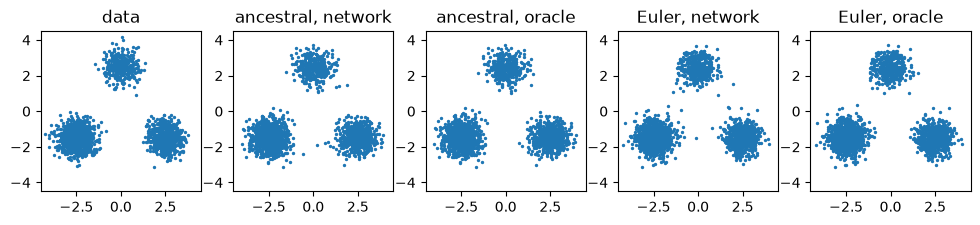

In [10]:
torch.manual_seed(5)
x_T = torch.randn(20_000, 2, device=device)
runs = {'data': mix.sample(20_000)}
for name, pred in (('network', pred_eps), ('oracle', oracle)):
    torch.manual_seed(6)                       # the same noise for both
    runs[f'ancestral, {name}'] = ancestral_sample(pred, x_T, vp, 200)
for name, pred in (('network', pred_v), ('oracle', oracle)):
    runs[f'Euler, {name}'] = ode_sample(pred, x_T, linear.sigma_bars(100))
for name, x in runs.items():
    print(f'{name:>18}:', mix.summary(x))
print('standard error of a weight:', [round(math.sqrt(w * (1 - w) / 20_000), 4)
                                      for w in mix.weights.tolist()])
mode = lambda x: ((x[:, None] - mix.means) ** 2).sum(-1).argmin(1)
for s in ('ancestral', 'Euler'):
    moved = mode(runs[s + ', network']) != mode(runs[s + ', oracle'])
    print(f'{s}: network and oracle end in different modes for '
          f'{moved.float().mean().item():.2%} of the starts')
d2l.scatter_panels([runs[k][:2000] for k in runs],
                   list(runs), lim=4.5, size=2.4);

<!-- d2l:prose id=integration-md-10 fw=all -->

In both samplers, the trained network and the exact oracle send only $0.2\%$ to $0.5\%$ of the 20,000 initial points to different modes, and every mode weight of a network run lies within $0.004$ of its paired oracle run (on the order of the binomial standard error $\approx 0.0035$). Both samplers also match the true data's spread (within $0.01$) and stray fraction ($\approx 1.1\%$, the Gaussian tail beyond $3s$).

At 100–200 steps on the mixture, the deterministic ODE and the stochastic ancestral chain achieve virtually identical distributional accuracy. They differ in their structural properties: the probability-flow ODE defines a deterministic, invertible bijection between noise $\mathbf{x}_1$ and data $\mathbf{x}_0$, enabling latent interpolation and exact likelihood evaluation, whereas the ancestral chain injects Langevin noise that can damp discretization or score errors along the trajectory (that section). the table summarizes how the major generative models of this chapter combine a path, a target, and a sampler.

<!-- tbl-caption:The models of this chapter: the target and path that train the network, and the sampler that produces data. -->

| model | target and path | sampler | where |
|:--|:--|:--|:--|
| denoising score model | the score $-\boldsymbol\epsilon/\sigma$, at one level | Langevin dynamics | that section |
| noise-conditional score network | the score at each level of a ladder on the VE path, weighted by $\tilde\sigma^2$ | annealed Langevin dynamics | that section |
| DDPM | $\boldsymbol\epsilon$ on the VP path | the ancestral chain or the probability-flow ODE | that section, here |
| flow matching, rectified flow | $\boldsymbol\epsilon - \mathbf{x}_0$ on the linear path | Euler steps on the probability-flow ODE | that section, here |
| $\mathbf{v}$-prediction | $\mathbf{v}$ on the cosine path | either | that section, that section |
| EDM | the clean point on the VE path, rescaled per noise level | a second-order solver of the probability-flow ODE | that section, that section |

In that section we move from two dimensions to $28 \times 28$ images, where no exact oracle is available and every function evaluation requires a forward pass through a convolutional U-Net.

## Summary

The marginal velocity $\mathbf{u}_t(\mathbf{x}) = \mathbb{E}[\dot\alpha_t \mathbf{x}_0 + \dot\sigma_t \boldsymbol\epsilon \mid \mathbf{x}_t = \mathbf{x}]$ satisfies the continuity equation $\partial_t p_t + \nabla \cdot (p_t \mathbf{u}_t) = 0$ with the marginal density $p_t$, so integrating the probability-flow ODE $d\mathbf{x}/dt = \mathbf{u}_t(\mathbf{x})$ from $t = 1$ to $t = 0$ transports $\mathcal{N}(\mathbf{0}, \mathbf{I})$ onto $p_0$ while preserving mode weights. Although a single Euler step from $t = 1$ to $t = 0$ collapses every starting point onto the data mean $\mathbb{E}[\mathbf{x}_0]$, working in the rescaled coordinates $\bar{\mathbf{x}} = \mathbf{x}/\alpha_t$ and $\bar\sigma = \sigma_t/\alpha_t$ puts every Gaussian path into the common ODE $d\bar{\mathbf{x}}/d\bar\sigma = \hat{\boldsymbol\epsilon}$, whose Euler step reads $\mathbf{x}_s = \alpha_s \hat{\mathbf{x}}_0 + \sigma_s \hat{\boldsymbol\epsilon}$. To first order in the step variance $\beta$, DDPM's stochastic ancestral step decomposes into this probability-flow Euler step plus a Langevin step on $p_t$, corresponding to an Euler–Maruyama discretization of Anderson's reverse-time SDE.

## Exercises

1. **One step in two coordinate systems.**
    1. On the linear path, show that the step $\mathbf{x}_s = \alpha_s \hat{\mathbf{x}}_0 + \sigma_s \hat{\boldsymbol\epsilon}$ equals the Euler step $\mathbf{x}_t - (t - s)\, \mathbf{u}_t(\mathbf{x}_t)$ in $t$.
    1. Let the data be the single point $\mathbf{x}_0 = \mathbf{0}$, on any Gaussian path. Show that $\hat{\boldsymbol\epsilon} = \mathbf{x}/\sigma_t$, that the exact trajectory through $\mathbf{x}_t$ is $\mathbf{x}_s = (\sigma_s/\sigma_t)\, \mathbf{x}_t$, and that the step of the first part follows it exactly for every $s < t$.
    1. On the VP path the marginal velocity of these data is $\mathbf{u}_t(\mathbf{x}) = (\dot\sigma_t/\sigma_t)\, \mathbf{x}$, with $d\sigma_t^2/dt = \beta(t)\, \alpha_t^2$ and $\beta(t) = 0.1 + 19.9\, t$. Take one step from $t = 0.5$, where $\alpha_t \approx 0.28$ and $\sigma_t \approx 0.96$, to $s = 0.1$, where $\sigma_s \approx 0.32$. By what factor does the Euler step in $t$ multiply $\mathbf{x}$, and by what factor should it? What does this suggest about the coordinates in which a sampler with few steps should work?
1. **The ancestral step to first order, for Gaussian data.** ● Let the data be $\mathcal{N}(\mathbf{0}, v_0 \mathbf{I})$, so that on the VP path $p_t = \mathcal{N}(\mathbf{0}, v_t \mathbf{I})$ with $v_t = \alpha_t^2 v_0 + \sigma_t^2$.
    1. Show that one ancestral step the equation from $t$ to $s$ with the exact score and $\beta = 1 - \alpha_t^2/\alpha_s^2$ maps $p_t$ to $\mathcal{N}\big(\mathbf{0}, (v_s + \delta)\mathbf{I}\big)$ with $\delta = \beta^2 (1/v_t - 1)/(1 - \beta)$.
    1. For which data is the step exact? Is the variance too large or too small for data narrower than the standard Gaussian, such as one component of the mixture, $v_0 = 0.25$?
    1. How does the error accumulated over the chain change when the grid is refined to twice as many steps, each with about half the $\beta$?
1. **Step size and Gaussian reversal.** ● The ancestral chain uses Gaussian transitions, which are justified for small steps. This problem measures how small. Write $\sigma_{t|s}^2 = \sigma_t^2 - (\alpha_t/\alpha_s)^2 \sigma_s^2$ for the variance of the forward step from $s$ to $t > s$.
    1. Show that the exact reversal is the mixture $q(\mathbf{x}_s \mid \mathbf{x}_t) = \mathbb{E}_{\mathbf{x}_0 \mid \mathbf{x}_t}\big[q(\mathbf{x}_s \mid \mathbf{x}_t, \mathbf{x}_0)\big]$ and that its covariance is $\tau^2 \mathbf{I} + c^2\, \textrm{Cov}[\mathbf{x}_0 \mid \mathbf{x}_t]$, where $\tau^2 = \sigma_{t|s}^2 \sigma_s^2/\sigma_t^2$ is the variance of $q(\mathbf{x}_s \mid \mathbf{x}_t, \mathbf{x}_0)$ and $c = \alpha_s \sigma_{t|s}^2/\sigma_t^2$ is the coefficient of $\mathbf{x}_0$ in its mean.
    1. Let the data be $\pm 1$ with equal probability in one dimension, and let $x_t = 0$. Show that the reversal is the equal mixture of $\mathcal{N}(\pm c, \tau^2)$, which is bimodal exactly when $\zeta^2 = c^2/\tau^2$ exceeds one, and that $\zeta^2 = \alpha_s^2 \sigma_{t|s}^2 / (\sigma_t^2 \sigma_s^2)$. How does $\zeta$ shrink as the step $t - s$ is refined?
    1. Evaluate $\zeta$ on the VP path from $t = 0.5$ to $s = 0.495$, $0.45$ and $0.3$, and for one step from $t = 0.3$ to $s = 0$. Which reversals are bimodal? What does a Gaussian transition with the optimal mean produce at $x_t = 0$ in the last case, and what should it produce?
1. [code] **Commitment time.** ● When along the path does a sample decide its mode? @Biroli.Bonnaire.deBortoli.ea.2024 measure this by cloning: start at a point of $p_t$, run two copies of the reverse chain with independent noise, and record whether they end in the same mode.
    1. Draw $2{,}000$ clean points, noise them to $\mathbf{x}_t$ on the VP path for $t = 0.9, 0.7, 0.5, 0.4, 0.3, 0.2, 0.1$, and run two copies of `ancestral_sample(pred_eps, x_t, vp, steps, t_start=t)` from each with about $200\, t$ steps. Plot the fraction $\varphi(t)$ of pairs whose ends have the same nearest mean. Which value does $\varphi$ approach as $t \to 1$, and why?
    1. Let $\Lambda$ be the largest eigenvalue of the covariance of the data. Biroli et al. define the speciation time by $\alpha_t^2 \Lambda = 1$, where the signal along the top principal direction stops dominating the noise. Compute it for the mixture and compare it with your curve and with the annealing ladder of that section, whose coarse levels decided the mode weights. Exercise 2 of that section and Exercise 4 of that section work out the same question for two modes in one dimension.
1. **Same ratio, same flow.** ● Let two Gaussian paths have coefficients related by $\alpha^B_t = c_t\, \alpha^A_t$ and $\sigma^B_t = c_t\, \sigma^A_t$ for a smooth positive function $c_t$, so that they have the same log-SNR at every time.
    1. Show that $p^B_t(\mathbf{y}) = c_t^{-d}\, p^A_t(\mathbf{y}/c_t)$. Use the score–velocity identity of that section, $\mathbf{u}_t(\mathbf{x}) = (\dot\alpha_t/\alpha_t)\, \mathbf{x} - \big(\sigma_t \dot\sigma_t - \sigma_t^2 \dot\alpha_t/\alpha_t\big) \nabla \log p_t(\mathbf{x})$, to show that $\mathbf{u}^B_t(\mathbf{y}) = (\dot c_t / c_t)\, \mathbf{y} + c_t\, \mathbf{u}^A_t(\mathbf{y}/c_t)$. Conclude that the trajectories of the probability-flow ODE are related by $\mathbf{y}_t = c_t\, \mathbf{x}_t$.
    1. Let $\tau(t)$ be increasing. Show that the path $p_{\tau(t)}$ is generated by the field $\dot\tau(t)\, \mathbf{u}_{\tau(t)}$, with the same trajectories as $\mathbf{u}$.
    1. Find the change of time $\tau(t)$ for which the cosine path $(\cos\frac{\pi\tau}{2}, \sin\frac{\pi\tau}{2})$ at time $\tau(t)$ has the log-SNR of the linear path at time $t$, and show that $c_t = 1/\sqrt{(1 - t)^2 + t^2}$. Where along the path is the rescaling largest?
    1. What does the probability-flow ODE of the cosine path do to data distributed as $\mathcal{N}(\mathbf{0}, \mathbf{I})$, and why? What does that of the linear path do to the same data?

[Discussions](https://d2l.discourse.group/t/36889)